# Exploratory analysis: fiber-seq QC report (single sample)

This file will run with any python environment with numpy, pandas, matplotlib and scipy

One fibertools-rs QC report with columns `statistic`, `value`, `count`:

| statistic | value means | count means |
|---|---|---|
| `phased_reads` / `phased_bp` | haplotype (`H1`/`H2`/`UNK`) | reads / bp assigned to that haplotype |
| `ccs_passes` | CCS passes per read | number of reads |
| `read_quality` | read quality | number of reads |
| `fiber_length`, `msp_length`, `nuc_length` | length in bp | number of fibers / MSPs / nucleosomes |
| `cpg_count`, `msp_count`, `nuc_count`, `m6a_count` | count per fiber | number of fibers |
| `m6a_ratio` | m6A fraction per fiber | number of fibers |
| `read_length_per_nuc` | read length / nucleosome count | number of fibers (`inf` = fiber with 0 nucleosomes) |
| `m6a_acf` | lag (bp) | **autocorrelation value** (not a count) |



In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Config

In [ ]:
QC_FILE = '200sample_qc.tab' # change this to the location + your QC file. 

## Load & overview

In [ ]:
LABEL = Path(QC_FILE).name.removesuffix('_qc.tab') # the expected file name is <sample_name>_qc.txt

df = pd.read_csv(QC_FILE, sep='\t', dtype=str)
df['count'] = df['count'].astype(float)
df['number'] = pd.to_numeric(df['value'], errors='coerce')  # NaN for haplotype labels

total_reads = df.loc[df['statistic'] == 'phased_reads', 'count'].sum()  # H1 + H2 + UNK

print(LABEL, '-', len(df), 'rows')
print(f'Total reads: {total_reads:,.0f}')

# Methylation rate = m6A fraction per fiber (m6a_ratio), averaged over fibers weighted by count
m6a = df[df['statistic'] == 'm6a_ratio']
methylation_rate = (m6a['number'] * m6a['count']).sum() / m6a['count'].sum()
print(f'Methylation rate (mean m6A ratio per fiber): {100 * methylation_rate:.2f}%')
df['statistic'].value_counts().to_frame('n_rows')

sample200 - 194213 rows
Total reads: 92,744
Methylation rate (mean m6A ratio per fiber): 9.38%


,n_rows
statistic,
read_length_per_nuc,67199
ccs_passes,66491
fiber_length,25820
m6a_ratio,22461
m6a_count,3103
nuc_length,2936
msp_length,2194
m6a_acf,2001
read_quality,1001


## Phasing

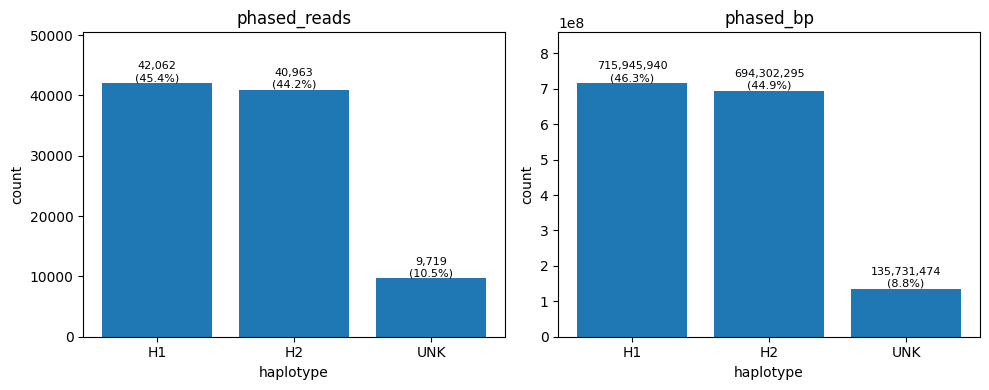

statistic,phased_bp,phased_reads
value,,
H1,46.31,45.35
H2,44.91,44.17
UNK,8.78,10.48


In [ ]:
phasing = df[df['statistic'].isin(['phased_reads', 'phased_bp'])]
phasing = phasing.pivot(index='value', columns='statistic', values='count')
percent = 100 * phasing / phasing.sum()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, stat in zip(axes, ['phased_reads', 'phased_bp']):
    bars = ax.bar(phasing.index, phasing[stat])
    labels = [f'{n:,.0f}\n({p:.1f}%)' for n, p in zip(phasing[stat], percent[stat])]
    ax.bar_label(bars, labels=labels, fontsize=8)
    ax.margins(y=0.2)
    ax.set_title(stat)
    ax.set_xlabel('haplotype')
    ax.set_ylabel('count')
plt.tight_layout()
plt.show()

percent.round(2)

## Distributions

Summary per statistic (all weighted by `count`):

- `n` – total number of reads / fibers / MSPs / nucleosomes
- `n_zero`, `pct_zero` – how many have value exactly 0
- `min`, `median`, `max`
- `mean`, `sd` – mean and standard deviation
- `mode` – most common value

Values of `inf` (e.g. `read_length_per_nuc` for fibers with 0 nucleosomes) are left out.

In [ ]:
def weighted_percentile(values, weights, q):
    """Value below which a fraction q of the total weight lies (values must be sorted)."""
    cumulative = np.cumsum(weights)
    return values[np.searchsorted(cumulative, q * cumulative[-1])]


def summarize(statistic):
    rows = df[(df['statistic'] == statistic) & ~np.isinf(df['number'])].sort_values('number')
    values = rows['number'].to_numpy()
    weights = rows['count'].to_numpy()

    n = weights.sum()
    mean = (values * weights).sum() / n
    n_zero = weights[values == 0].sum()
    return {
        'n': n,
        'n_zero': n_zero,
        'pct_zero': 100 * n_zero / n,
        'min': values[0],
        'median': weighted_percentile(values, weights, 0.50),
        'max': values[-1],
        'mean': mean,
        'sd': np.sqrt((weights * (values - mean) ** 2).sum() / n),
        'mode': values[weights.argmax()],
    }

Each plot shows `value` vs `count` (log y), with the **mean** (red dashed)
and **median** (black). The x-axis stops where 99.5% of the counts are
covered, so the long tail doesn't hide the bulk.

`bin_width` groups nearby values for plotting only (needed for statistics with
many distinct decimal values, like `m6a_ratio`); the summary table always
uses the raw values.

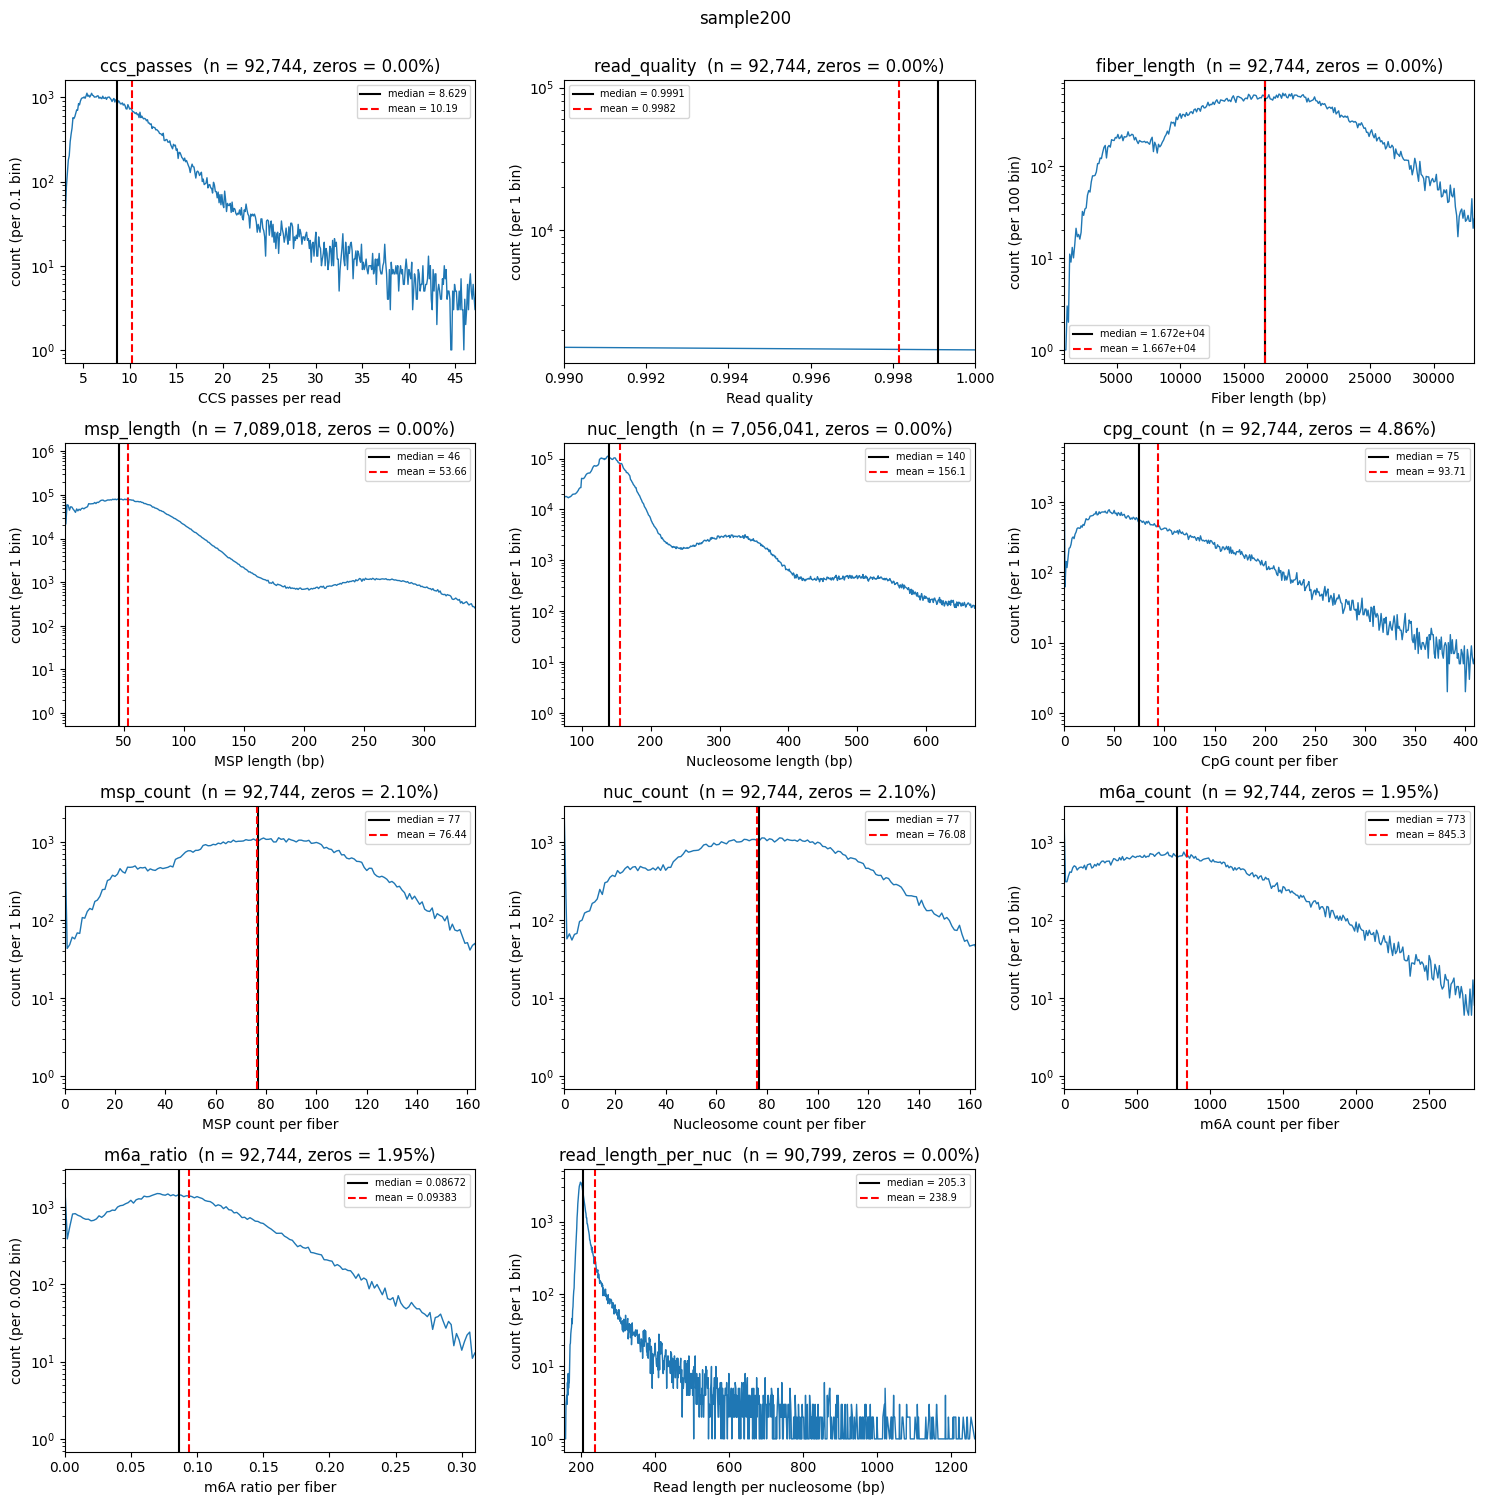

,n,n_zero,pct_zero,min,median,max,mean,sd,mode
ccs_passes,92744.0,0.0,0.0000,3.0047,8.6287,60.0000,10.1945,6.5090,5.3702
read_quality,92744.0,0.0,0.0000,0.9900,0.9991,1.0000,0.9982,0.0022,1.0000
fiber_length,92744.0,0.0,0.0000,853.0000,16725.0000,45648.0000,16669.3232,6293.4249,28551.0000
msp_length,7089018.0,0.0,0.0000,1.0000,46.0000,13318.0000,53.6617,65.6740,1.0000
nuc_length,7056041.0,0.0,0.0000,75.0000,140.0000,12424.0000,156.0955,95.8864,138.0000
cpg_count,92744.0,4506.0,4.8585,0.0000,75.0000,895.0000,93.7109,76.6816,0.0000
msp_count,92744.0,1951.0,2.1036,0.0000,77.0000,236.0000,76.4364,34.0104,0.0000
nuc_count,92744.0,1945.0,2.0972,0.0000,77.0000,236.0000,76.0808,33.9877,0.0000
m6a_count,92744.0,1813.0,1.9548,0.0000,773.0000,7822.0000,845.3105,565.8696,0.0000
m6a_ratio,92744.0,1813.0,1.9548,0.0000,0.0867,0.7335,0.0938,0.0599,0.0000


In [ ]:
# (statistic, x-axis label, bin width used for plotting)
DISTRIBUTIONS = [
    ('ccs_passes', 'CCS passes per read', 0.1),
    ('read_quality', 'Read quality', 1),
    ('fiber_length', 'Fiber length (bp)', 100),
    ('msp_length', 'MSP length (bp)', 1),
    ('nuc_length', 'Nucleosome length (bp)', 1),
    ('cpg_count', 'CpG count per fiber', 1),
    ('msp_count', 'MSP count per fiber', 1),
    ('nuc_count', 'Nucleosome count per fiber', 1),
    ('m6a_count', 'm6A count per fiber', 10),
    ('m6a_ratio', 'm6A ratio per fiber', 0.002),
    ('read_length_per_nuc', 'Read length per nucleosome (bp)', 1),
]

summary = {}
fig, axes = plt.subplots(4, 3, figsize=(15, 15))
for ax, (statistic, xlabel, bin_width) in zip(axes.flat, DISTRIBUTIONS):
    s = summarize(statistic)
    summary[statistic] = s

    rows = df[(df['statistic'] == statistic) & ~np.isinf(df['number'])]
    binned = rows.groupby(rows['number'] // bin_width * bin_width)['count'].sum()
    x_max = weighted_percentile(binned.index.to_numpy(), binned.to_numpy(), 0.995)

    ax.plot(binned.index, binned.values, linewidth=1)
    ax.axvline(s['median'], color='black', label=f"median = {s['median']:.4g}")
    ax.axvline(s['mean'], color='red', linestyle='--', label=f"mean = {s['mean']:.4g}")

    ax.set_xlim(s['min'], x_max)
    ax.set_yscale('log')
    ax.set_title(f"{statistic}  (n = {s['n']:,.0f}, zeros = {s['pct_zero']:.2f}%)")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f'count (per {bin_width} bin)')
    ax.legend(fontsize=7)

axes.flat[-1].set_visible(False)  # 11 plots in a 4x3 grid
fig.suptitle(LABEL, y=1.0)
plt.tight_layout()
plt.show()

pd.DataFrame(summary).T.round(4)

### Zoom: MSP length 10–400 bp (linear y)

Also reports the % of MSPs longer than 500 bp. MSPs that long usually mean the
region didn't get m6A-treated, not that it's really accessible.

MSPs > 400 bp: 0.38%


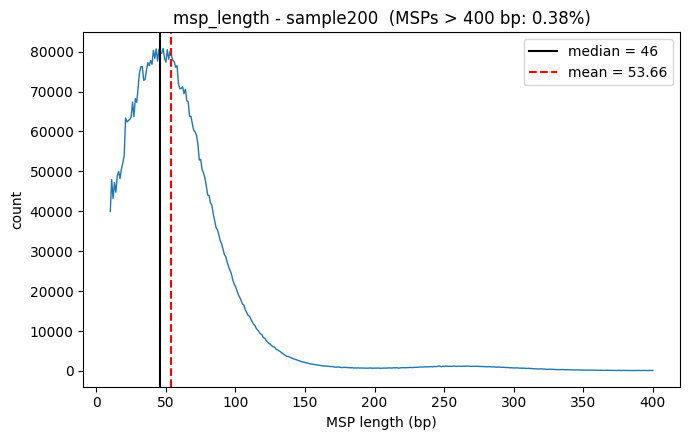

In [ ]:
msp = df[(df['statistic'] == 'msp_length') & df['number'].between(10, 400)].sort_values('number')
s = summary['msp_length']

all_msp = df[df['statistic'] == 'msp_length']
pct_over_400 = 100 * all_msp.loc[all_msp['number'] > 400, 'count'].sum() / all_msp['count'].sum()
print(f'MSPs > 400 bp: {pct_over_400:.2f}%')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(msp['number'], msp['count'], linewidth=1)
ax.axvline(s['median'], color='black', label=f"median = {s['median']:.4g}")
ax.axvline(s['mean'], color='red', linestyle='--', label=f"mean = {s['mean']:.4g}")
ax.set_xlabel('MSP length (bp)')
ax.set_ylabel('count')
ax.set_title(f'msp_length - {LABEL}  (MSPs > 400 bp: {pct_over_400:.2f}%)')
ax.legend()
plt.tight_layout()
plt.show()

## m6A autocorrelation (`m6a_acf`)

Here `count` is the autocorrelation at each lag (`value`). Marked on the plots:

- the **mean** autocorrelation (lags > 0 on the left, lags > 25 bp in the middle, lags 1–250 bp on the right)
- in the 1–250 bp panel, the lags where the curve **crosses 0** (green) – found on a 21 bp rolling mean so noise around 0
  doesn't create extra crossings

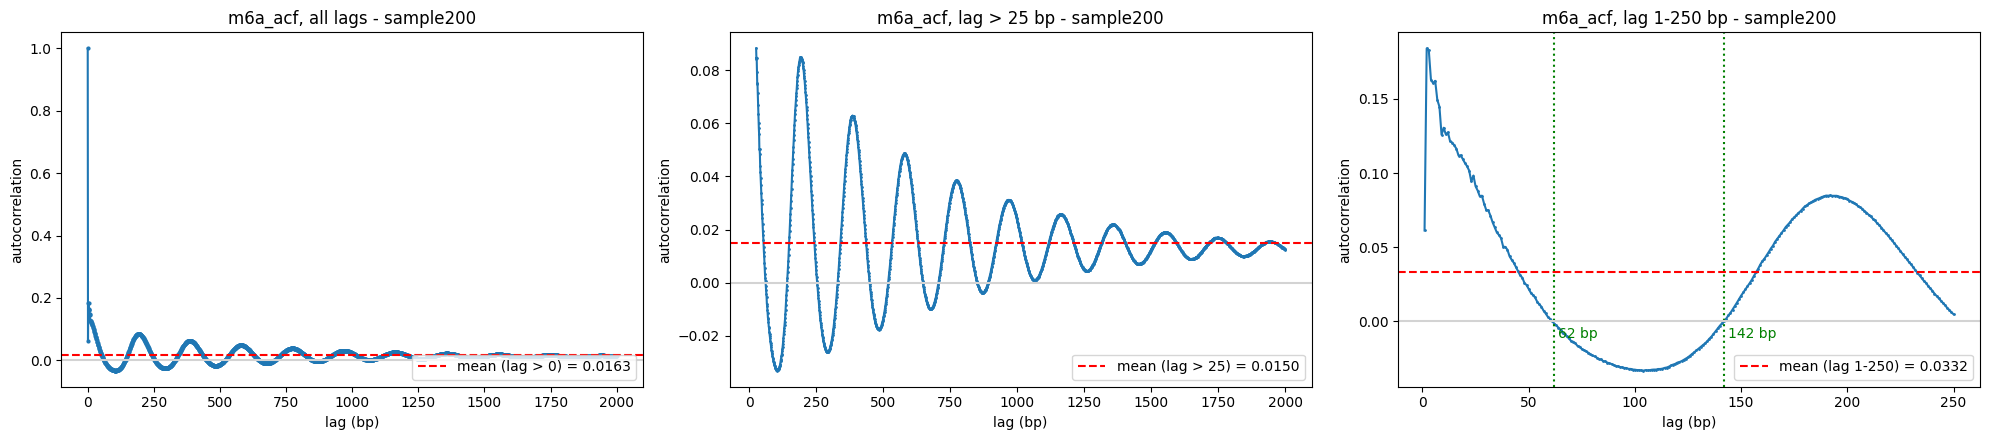

,sample200
"zero crossings, lag 1-250 (bp)","62, 142"


In [ ]:
acf = df[df['statistic'] == 'm6a_acf'].sort_values('number')
lags, values = acf['number'], acf['count']

mean_all = values[lags > 0].mean()
mean_after_25 = values[lags > 25].mean()
mean_up_to_250 = values[(lags > 0) & (lags <= 250)].mean()

# Zero crossings in lags 1-250: lags where the sign differs from the previous lag.
# Uses a 21 bp rolling mean so noise around 0 doesn't create extra crossings.
first_250_smoothed = values[(lags > 0) & (lags <= 250)].rolling(21, center=True, min_periods=1).mean()
sign_change = np.sign(first_250_smoothed) != np.sign(first_250_smoothed.shift())
zero_crossings = lags[sign_change.index[sign_change]].iloc[1:].tolist()  # first row has no previous lag

fig, (left, right, first_250) = plt.subplots(1, 3, figsize=(20, 4.5))

left.plot(lags, values, marker='o', markersize=2)
left.axhline(mean_all, color='red', linestyle='--', label=f'mean (lag > 0) = {mean_all:.4f}')
left.set_title(f'm6a_acf, all lags - {LABEL}')

right.plot(lags[lags > 25], values[lags > 25], marker='o', markersize=1)
right.axhline(mean_after_25, color='red', linestyle='--', label=f'mean (lag > 25) = {mean_after_25:.4f}')
right.set_title(f'm6a_acf, lag > 25 bp - {LABEL}')

up_to_250 = (lags > 0) & (lags <= 250)
first_250.plot(lags[up_to_250], values[up_to_250], marker='o', markersize=1)
first_250.axhline(mean_up_to_250, color='red', linestyle='--', label=f'mean (lag 1-250) = {mean_up_to_250:.4f}')
for crossing in zero_crossings:
    first_250.axvline(crossing, color='green', linestyle=':')
    first_250.annotate(f'{crossing:.0f} bp', xy=(crossing, 0), xytext=(3, -12), textcoords='offset points', color='green')
first_250.set_title(f'm6a_acf, lag 1-250 bp - {LABEL}')

for ax in (left, right, first_250):
    ax.axhline(0, color='lightgrey')
    ax.set_xlabel('lag (bp)')
    ax.set_ylabel('autocorrelation')
    ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

pd.Series({
    'zero crossings, lag 1-250 (bp)': ', '.join(f'{c:.0f}' for c in zero_crossings),
}).to_frame(LABEL)

### Chromatin Signal-to-Noise (CSN)

- **Signal** = area between the *smoothed* ACF and y = 0 (fluctuation due to nucleosome positioning), shaded yellow
- **Noise** = area between the *observed* and *smoothed* ACF (fluctuation due to anything else), see inset
- **CSN** = Signal / Noise
- **Peaks** = number of peaks in the smoothed ACF (dashed vertical lines; peaks closer than `MIN_PEAK_DISTANCE` count as one)

Signal and noise are measured from the **first trough** of the smoothed ACF
(the bottom of the initial drop after lag 0) to the last lag, so the
lag-0 spike and the initial decay are not counted as signal.

Smoothing uses a Savitzky–Golay filter (`SMOOTH_WINDOW` bp wide), which keeps
peak heights, unlike a plain rolling mean. Lags are 1 bp apart, so each area
is just a sum.

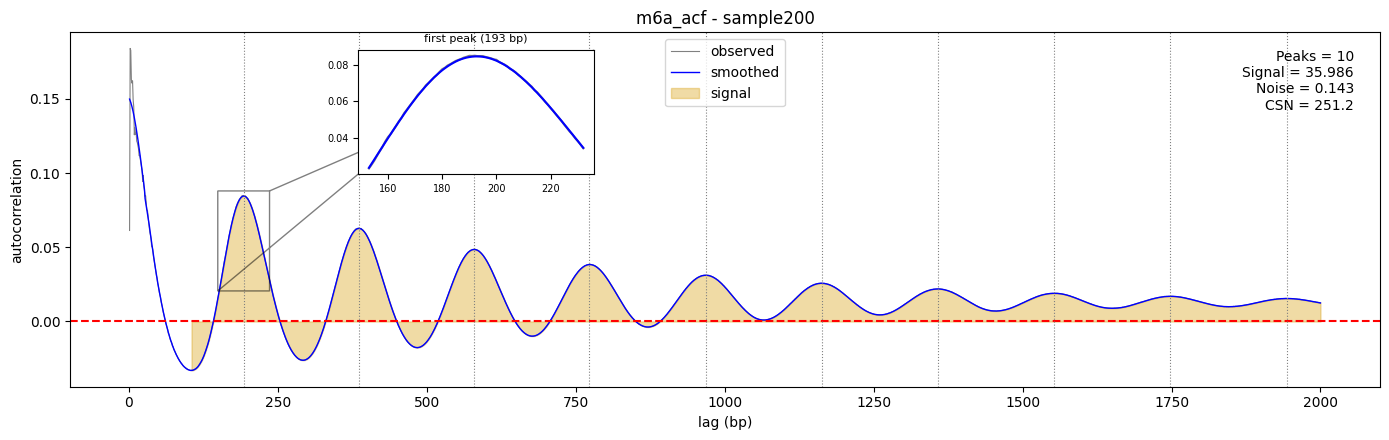

,sample200
signal start (bp),105.0
peaks,10
peak lags (bp),"193, 386, 579, 773, 968, 1163, 1358, 1553, 174..."
signal,35.985929
noise,0.143262
CSN,251.188835


In [ ]:
from scipy.signal import savgol_filter, find_peaks

SMOOTH_WINDOW = 51       # bp, must be odd
MIN_PEAK_DISTANCE = 100  # bp, peaks/troughs closer than this are treated as wiggles

# Smooth everything except lag 0, so the spike doesn't leak into nearby lags.
acf_lags = lags[lags > 0].to_numpy()
observed = values[lags > 0].to_numpy()
smoothed = savgol_filter(observed, SMOOTH_WINDOW, polyorder=3)

troughs, _ = find_peaks(-smoothed, distance=MIN_PEAK_DISTANCE)
start = troughs[0]                               # first trough after the initial decay
peaks, _ = find_peaks(smoothed[start:], height=0, distance=MIN_PEAK_DISTANCE)
peaks += start

signal = np.abs(smoothed[start:]).sum()
noise = np.abs(observed[start:] - smoothed[start:]).sum()
csn = signal / noise

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(acf_lags, observed, color='grey', linewidth=0.8, label='observed')
ax.plot(acf_lags, smoothed, color='blue', linewidth=1, label='smoothed')
ax.fill_between(acf_lags[start:], smoothed[start:], 0, color='goldenrod', alpha=0.4, label='signal')
ax.axhline(0, color='red', linestyle='--')
for peak in peaks:
    ax.axvline(acf_lags[peak], color='grey', linestyle=':', linewidth=0.8)
ax.text(0.98, 0.95, f'Peaks = {len(peaks)}\nSignal = {signal:.3f}\nNoise = {noise:.3f}\nCSN = {csn:.1f}',
        transform=ax.transAxes, ha='right', va='top')
ax.set_xlabel('lag (bp)')
ax.set_ylabel('autocorrelation')
ax.set_title(f'm6a_acf - {LABEL}')
ax.legend(loc='upper center')

# Inset: zoom on the first peak to show the noise (observed vs smoothed)
first_peak = peaks[0]
zoom = slice(first_peak - 40, first_peak + 40)
inset = ax.inset_axes([0.22, 0.6, 0.18, 0.35])
inset.plot(acf_lags[zoom], observed[zoom], color='grey')
inset.plot(acf_lags[zoom], smoothed[zoom], color='blue')
inset.set_title(f'first peak ({acf_lags[first_peak]:.0f} bp)', fontsize=8)
inset.tick_params(labelsize=7)
ax.indicate_inset_zoom(inset, edgecolor='black')

plt.tight_layout()
plt.show()

pd.Series({
    'signal start (bp)': acf_lags[start],
    'peaks': len(peaks),
    'peak lags (bp)': ', '.join(f'{acf_lags[p]:.0f}' for p in peaks),
    'signal': signal,
    'noise': noise,
    'CSN': csn,
}).to_frame(LABEL)